# BP Category Classification: Model Comparison

**Component 3: Hypertension Dietary Risk Assessment System**

This notebook tests whether dietary information improves the classification of blood pressure (BP) category beyond demographic information alone. Three feature sets are compared across three classifiers:

| Feature set | Variables |
|---|---|
| Demographic only (baseline) | age, sex, BMI |
| Demographic + day 1 diet | baseline + sodium, potassium, Na:K ratio, energy, saturated fat (day 1) |
| Demographic + multi-day diet | baseline + the same nutrients averaged over the available recalls |

**Classifiers:** Logistic Regression, Random Forest and XGBoost.

**Evaluation:** macro-averaged F1 is the primary metric because the classes are imbalanced and each class should count equally. Accuracy, macro precision and macro recall are also reported.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

SEED = 42          # fixed for reproducibility
TEST_SIZE = 0.2
N_FOLDS = 5
OLDER_AGE = 60     # threshold for the older-adult subset

DATA_PATH = Path("../data/processed/nhanes_bp_diet.csv")
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(exist_ok=True)

## 1. Data and feature sets

The prepared dataset from notebook 01 is loaded and the BP category is converted to numeric codes. The averaged BP columns are kept in the file for reference only; the code verifies that they are not used as features.

In [2]:
df = pd.read_csv(DATA_PATH)

categories = ["Normal", "Elevated", "Stage 1", "Stage 2"]
df["label"] = df["bp_category"].map({c: i for i, c in enumerate(categories)})

DEMOGRAPHIC = ["age", "sex_female", "bmi"]
DIET_DAY1 = ["sodium_mg_day1", "potassium_mg_day1", "energy_kcal_day1",
             "sat_fat_g_day1", "na_k_ratio_day1"]
DIET_MULTIDAY = ["sodium_mg_mean", "potassium_mg_mean", "energy_kcal_mean",
                 "sat_fat_g_mean", "na_k_ratio_mean"]

FEATURE_SETS = {
    "Demographic only": DEMOGRAPHIC,
    "Demographic + day 1 diet": DEMOGRAPHIC + DIET_DAY1,
    "Demographic + multi-day diet": DEMOGRAPHIC + DIET_MULTIDAY,
}
MODELS = ["Logistic Regression", "Random Forest", "XGBoost"]

all_features = sorted({f for features in FEATURE_SETS.values() for f in features})
assert not set(all_features) & {"systolic_avg", "diastolic_avg"}, "BP variable used as feature"
assert df[all_features + ["label"]].notna().all().all(), "Unexpected missing values"

print(f"{len(df)} participants")

7473 participants


## 2. Train/test split

An 80/20 split is made once, stratified by BP category so that each class has the same proportion in both parts. The test set is used only for the final evaluation in section 5; model selection and cross-validation use the training set alone.

In [3]:
train, test = train_test_split(df, test_size=TEST_SIZE, stratify=df["label"], random_state=SEED)

split_counts = pd.DataFrame({
    "train": train["bp_category"].value_counts().reindex(categories),
    "test": test["bp_category"].value_counts().reindex(categories),
})
print(split_counts)
print(f"\nTrain: {len(train)}   Test: {len(test)}")
print(f"Test participants aged {OLDER_AGE}+: {(test['age'] >= OLDER_AGE).sum()}")

             train  test
bp_category             
Normal        2623   656
Elevated       842   211
Stage 1       1243   311
Stage 2       1270   317

Train: 5978   Test: 1495
Test participants aged 60+: 510


## 3. Models

All classifiers use default hyperparameters; no tuning is performed, so the test set cannot influence model settings. Class imbalance is handled with balanced class weights (balanced sample weights for XGBoost). Logistic Regression is preceded by standardisation because it is sensitive to feature scale.

In [4]:
def make_model(name):
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(),
                             LogisticRegression(max_iter=1000, class_weight="balanced"))
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                      random_state=SEED, n_jobs=-1)
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                         eval_metric="mlogloss", random_state=SEED)


def fit_predict(name, X_train, y_train, X_eval):
    model = make_model(name)
    if name == "XGBoost":
        model.fit(X_train, y_train, sample_weight=compute_sample_weight("balanced", y_train))
    else:
        model.fit(X_train, y_train)
    return model.predict(X_eval)


def cross_validate(data, features):
    """Mean and standard deviation of macro-F1 over stratified folds."""
    X, y = data[features].to_numpy(), data["label"].to_numpy()
    folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    scores = {m: [] for m in MODELS}
    for fit_idx, val_idx in folds.split(X, y):
        for m in MODELS:
            pred = fit_predict(m, X[fit_idx], y[fit_idx], X[val_idx])
            scores[m].append(f1_score(y[val_idx], pred, average="macro"))
    return {m: (np.mean(s), np.std(s)) for m, s in scores.items()}

## 4. Cross-validation on the training set

Five-fold stratified cross-validation gives the macro-F1 of every combination of feature set and classifier. The best combination is chosen from these results, not from the test set.

In [5]:
cv_rows = []
for set_name, features in FEATURE_SETS.items():
    for model_name, (mean, std) in cross_validate(train, features).items():
        cv_rows.append({"feature_set": set_name, "model": model_name,
                        "cv_macro_f1": round(mean, 4), "cv_std": round(std, 4)})

cv_results = pd.DataFrame(cv_rows)
print(cv_results.pivot(index="feature_set", columns="model", values="cv_macro_f1")
                .loc[list(FEATURE_SETS)][MODELS])

best = cv_results.loc[cv_results["cv_macro_f1"].idxmax()]
print(f"\nBest by cross-validation: {best['model']} with {best['feature_set']} "
      f"(macro-F1 {best['cv_macro_f1']:.3f})")

model                         Logistic Regression  Random Forest  XGBoost
feature_set                                                              
Demographic only                           0.3521         0.3250   0.3561
Demographic + day 1 diet                   0.3589         0.3611   0.3591
Demographic + multi-day diet               0.3563         0.3599   0.3621

Best by cross-validation: XGBoost with Demographic + multi-day diet (macro-F1 0.362)


## 5. Test set evaluation

Each combination is fitted on the full training set and evaluated once on the test set, for all adults and for the older-adult subset (age >= `OLDER_AGE`). The older-adult rows are taken from the test set only, so no participant used for training is evaluated.

In [6]:
older_mask = (test["age"] >= OLDER_AGE).to_numpy()
y_test = test["label"].to_numpy()


def metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


predictions, test_rows = {}, []
for set_name, features in FEATURE_SETS.items():
    for model_name in MODELS:
        pred = fit_predict(model_name, train[features].to_numpy(), train["label"].to_numpy(),
                           test[features].to_numpy())
        predictions[(set_name, model_name)] = pred
        test_rows.append({"feature_set": set_name, "model": model_name, "group": "All adults",
                          **metrics(y_test, pred)})
        test_rows.append({"feature_set": set_name, "model": model_name,
                          "group": f"Age {OLDER_AGE}+",
                          **metrics(y_test[older_mask], pred[older_mask])})

test_results = pd.DataFrame(test_rows).round(4)

for group, part in test_results.groupby("group", sort=False):
    n = len(y_test) if group == "All adults" else older_mask.sum()
    print(f"\nTest macro-F1, {group} (n = {n})")
    print(part.pivot(index="feature_set", columns="model", values="macro_f1")
              .loc[list(FEATURE_SETS)][MODELS])


Test macro-F1, All adults (n = 1495)
model                         Logistic Regression  Random Forest  XGBoost
feature_set                                                              
Demographic only                           0.3575         0.3082   0.3651
Demographic + day 1 diet                   0.3502         0.3606   0.3653
Demographic + multi-day diet               0.3582         0.3725   0.3696

Test macro-F1, Age 60+ (n = 510)
model                         Logistic Regression  Random Forest  XGBoost
feature_set                                                              
Demographic only                           0.1669         0.2505   0.2081
Demographic + day 1 diet                   0.1895         0.2414   0.2377
Demographic + multi-day diet               0.1926         0.2634   0.2372


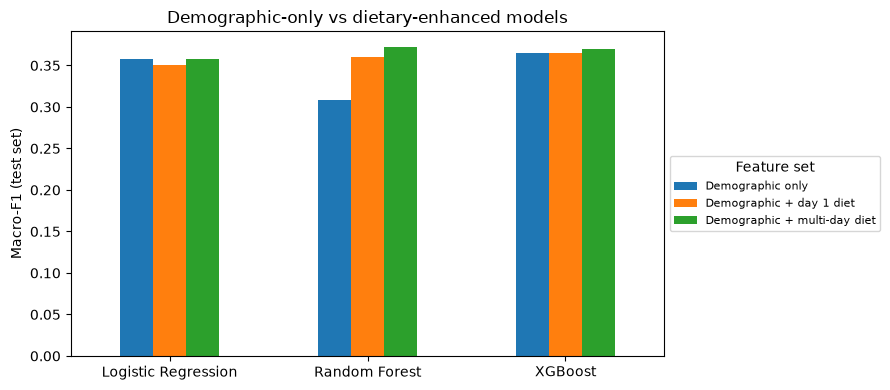

In [7]:
plot_data = (test_results[test_results["group"] == "All adults"]
             .pivot(index="model", columns="feature_set", values="macro_f1")
             .loc[MODELS][list(FEATURE_SETS)])

ax = plot_data.plot(kind="bar", figsize=(9, 4), rot=0)
ax.set_ylabel("Macro-F1 (test set)")
ax.set_xlabel("")
ax.set_title("Demographic-only vs dietary-enhanced models")
ax.legend(title="Feature set", fontsize=8, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.tight_layout()
plt.savefig(RESULTS_DIR / "macro_f1_by_feature_set.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Per-class performance of the best model

The combination selected by cross-validation is examined in detail. Per-class precision and recall show which BP categories are classified well, and the confusion matrix shows where errors occur.

XGBoost | Demographic + multi-day diet

              precision    recall  f1-score   support

      Normal       0.69      0.51      0.59       656
    Elevated       0.19      0.23      0.20       211
     Stage 1       0.27      0.25      0.26       311
     Stage 2       0.36      0.52      0.43       317

    accuracy                           0.42      1495
   macro avg       0.38      0.38      0.37      1495
weighted avg       0.46      0.42      0.43      1495



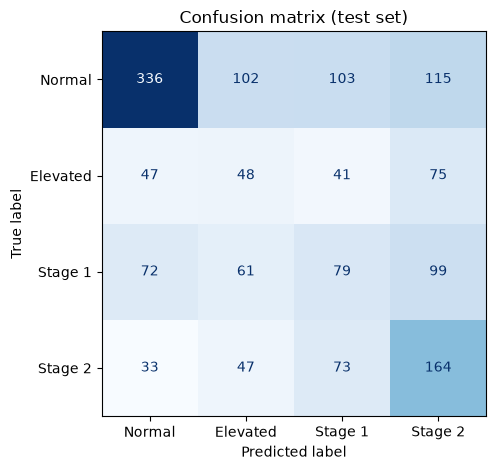

In [8]:
best_key = (best["feature_set"], best["model"])
best_pred = predictions[best_key]
print(f"{best['model']} | {best['feature_set']}\n")
print(classification_report(y_test, best_pred, target_names=categories, zero_division=0))

cm = confusion_matrix(y_test, best_pred, labels=range(len(categories)))
ConfusionMatrixDisplay(cm, display_labels=categories).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix (test set)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix_best_model.png", dpi=150)
plt.show()

## 7. Older-adult-only analysis

As a secondary analysis, the models are trained and cross-validated using only participants aged `OLDER_AGE` and over. This indicates whether the dietary features add more information in a population with less age variation. Because this subset is smaller, the results are less stable, particularly for the Elevated class.

In [9]:
older = df[df["age"] >= OLDER_AGE]
print(f"{len(older)} participants aged {OLDER_AGE}+")
print(older["bp_category"].value_counts().reindex(categories).to_string())

older_rows = []
for set_name, features in FEATURE_SETS.items():
    for model_name, (mean, std) in cross_validate(older, features).items():
        older_rows.append({"feature_set": set_name, "model": model_name,
                           "cv_macro_f1": round(mean, 4), "cv_std": round(std, 4)})

older_results = pd.DataFrame(older_rows)
print(f"\nCross-validated macro-F1, age {OLDER_AGE}+ only")
print(older_results.pivot(index="feature_set", columns="model", values="cv_macro_f1")
                   .loc[list(FEATURE_SETS)][MODELS])

2557 participants aged 60+
bp_category
Normal      653
Elevated    452
Stage 1     538
Stage 2     914

Cross-validated macro-F1, age 60+ only
model                         Logistic Regression  Random Forest  XGBoost
feature_set                                                              
Demographic only                           0.2661         0.2690   0.2647
Demographic + day 1 diet                   0.2935         0.2787   0.2766
Demographic + multi-day diet               0.2841         0.2612   0.2680


## 8. Save results

In [10]:
split_counts.to_csv(RESULTS_DIR / "split_counts.csv")
cv_results.to_csv(RESULTS_DIR / "cv_results.csv", index=False)
test_results.to_csv(RESULTS_DIR / "test_results.csv", index=False)
older_results.to_csv(RESULTS_DIR / "older_adult_cv_results.csv", index=False)
print("Results saved to", RESULTS_DIR.resolve())

Results saved to /Users/savindi/Desktop/research/Wellness Platform /project/Hypertension-Management-Ecosystem/ai/component3-nutrition/results
